INFO: No transforms provided; using empty ConfigTransformManager.
INFO: File training_healthy.h5 already exists. Skipping download.
INFO: File dataset_anomalies.h5 already exists. Skipping download.
INFO: File ground_truth.csv already exists. Skipping download.
INFO: Reading /home/levtel/projects/TabPHM/datasets/training_healthy.h5...


Loading configuration with overrides: ['datasource=airbus_helicopter', 'datasource.task_mode=detection']
Preprocessor Mode: per_unit
Running Preprocessing Pipeline...


Processing train: 100%|██████████| 1677/1677 [00:00<00:00, 2274.87seq/s]
INFO: Reading /home/levtel/projects/TabPHM/datasets/dataset_anomalies.h5...
Processing test: 100%|██████████| 594/594 [00:00<00:00, 3072.29seq/s]
INFO: Loaded Airbus Data: 1677 train, 594 test, 594 validation sequences.


                               Data Transforms Summary                               
┏━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━┳━━━━━━━━━┳━━━━━━━━┓
┃ Transform Name ┃ Time (s) ┃ Status ┃ Details ┃ Changes ┃ Added ┃ Removed ┃ Inputs ┃
┡━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━╇━━━━━━━━━╇━━━━━━━━┩
└────────────────┴──────────┴────────┴─────────┴─────────┴───────┴─────────┴────────┘

INFO: Applied transforms and saved result to Stage 2 cache.
INFO: Data dictionary structure after transforms:


data_dict
├── features SplitDatasetContainer
│   ├── train: list<ak.Array> x 1677 shape[60, 'var', 1] (min/max/mean):
│   │   ├── dim 0: 60 / 60 / 60.0
│   │   ├── dim 1 (var): 1024 / 1024 / 1024.0
│   │   └── dim 2: 1 / 1 / 1.0
│   ├── val: list<ak.Array> x 594 shape[60, 'var', 1] (min/max/mean):
│   │   ├── dim 0: 60 / 60 / 60.0
│   │   ├── dim 1 (var): 1024 / 1024 / 1024.0
│   │   └── dim 2: 1 / 1 / 1.0
│   └── test: list<ak.Array> x 594 shape[60, 'var', 1] (min/max/mean):
│       ├── dim 0: 60 / 60 / 60.0
│       ├── dim 1 (var): 1024 / 1024 / 1024.0
│       └── dim 2: 1 / 1 / 1.0
├── target SplitDatasetContainer
│   ├── train: list<ak.Array> x 1677 shape[60, 'var', 1] (min/max/mean):
│   │   ├── dim 0: 60 / 60 / 60.0
│   │   ├── dim 1 (var): 1 / 1 / 1.0
│   │   └── dim 2: 1 / 1 / 1.0
│   ├── val: list<ak.Array> x 594 shape[60, 'var', 1] (min/max/mean):
│   │   ├── dim 0: 60 / 60 / 60.0
│   │   ├── dim 1 (var): 1 / 1 / 1.0
│   │   └── dim 2: 1 / 1 / 1.0
│   └── test: list<ak.Array> x 594 shape[60, 'var', 1] (min/max/mean):
│       ├── dim 0: 60 / 60 / 60.0
│       ├── dim 1 (var): 1 / 1 / 1.0
│       └── dim 2: 1 / 1 / 1.0
└── unit_id SplitDatasetContainer
    ├── train: list<ndarray> x 1677 [np.ndarray(1,), ...\]
    ├── val: list<ndarray> x 594 [np.ndarray(1,), ...\]
    └── test: list<ndarray> x 594 [np.ndarray(1,), ...\]


Data Loaded Successfully!
Train Keys: dict_keys(['features', 'target', 'unit_id'])
Train Features Type: <class 'list'>


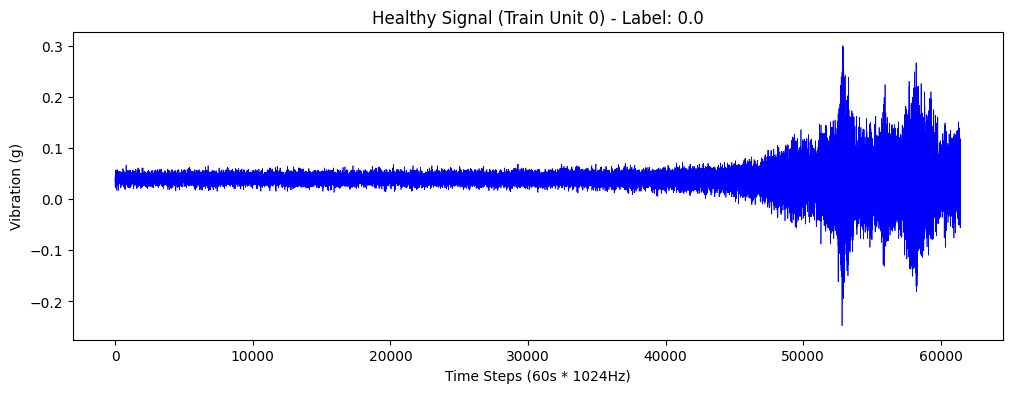

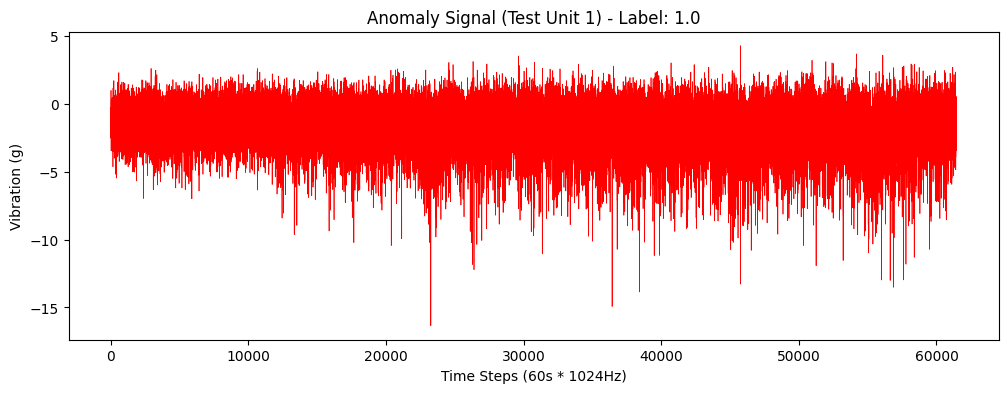

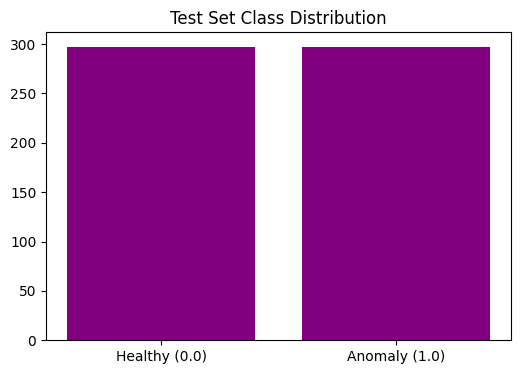

In [1]:
import hydra
from pathlib import Path
import matplotlib.pyplot as plt
import awkward as ak

# Internal Library Imports
from picid.data.datasources.base.multi_source_loader import MultiSourceLoader
from picid.data.datasources.base.phmd_loader import PHMDMultiSourceLoader
from picid.data.datasources.base.single_source_loader import SingleSourceLoader
from picid.data.datasources.base.interfaces import AbstractDataSourceLoader
from picid.data.preprocessing.preprocessor import PreProcessor

# %load_ext autoreload
# %autoreload 2

# --- CONFIGURATION ---
# We use the datasource config we created earlier.
# If you have an experiment config, you can switch to f"experiment=airbus_helicopter"
target_config_name = "run.yaml"
overrides = [
    "datasource=airbus_helicopter",  # Loads configs/datasource/airbus_helicopter.yaml
    "datasource.task_mode=detection",
]

# Initialize Hydra and Load
with hydra.initialize(version_base="1.3", config_path="../configs", job_name="run"):
    print(f"Loading configuration with overrides: {overrides}")
    cfg = hydra.compose(
        config_name=target_config_name,
        overrides=overrides,
        return_hydra_config=True,
    )

    # 1. Instantiate the Airbus Loader
    dataset_source = hydra.utils.instantiate(cfg.datasource)

    # 3. Determine Preprocessor Mode
    # Airbus data is structured as independent units/sequences, so 'per_unit' is appropriate.
    # Note: We check against AbstractDataSourceLoader to include our new class.
    if isinstance(
        dataset_source,
        (SingleSourceLoader, PHMDMultiSourceLoader, AbstractDataSourceLoader),
    ):
        preprocessor_mode = "per_unit"
    elif isinstance(dataset_source, MultiSourceLoader):
        preprocessor_mode = "cross_unit"
    else:
        raise ValueError(f"Invalid dataset source type: {type(dataset_source)}")

    print(f"Preprocessor Mode: {preprocessor_mode}")
    preprocessor = PreProcessor(preprocessor_mode, dataset_source)

    # 4. Define Cache Paths (Standard Logic)
    use_cache = (
        cfg.cache.use_cache_after_loading or cfg.cache.use_cache_after_transfroms
    )

    data_cache_path = cfg.paths.cache_path if use_cache else None

    data_library_part_path = (
        Path(cfg.paths.root_dir) / "picid/data/datasources" if use_cache else None
    )
    transform_library_part_path = (
        Path(cfg.paths.root_dir) / "picid/transforms" if use_cache else None
    )

    # 5. Run Pipeline
    print("Running Preprocessing Pipeline...")
    preprocessor.pipeline(
        data_cache_path=data_cache_path,
        data_library_part_path=data_library_part_path,
        transform_library_part_path=transform_library_part_path,
        cache_preprocessed=cfg.cache.use_cache_after_transfroms,
    )

    # 6. Retrieve Data
    data_dict = preprocessor.get_processed_data_dict(return_splits_on_first_level=True)
    meta_data = preprocessor.get_meta_data_dict()

    print("\nData Loaded Successfully!")
    print(f"Train Keys: {data_dict['train'].keys()}")

    # --- VISUALIZATION (Tailored for Airbus Ragged Data) ---

    # Extract features and targets
    # These are LISTS of Awkward Arrays, not one big array yet
    train_feat = data_dict["train"]["features"]
    train_targ = data_dict["train"]["target"]
    test_feat = data_dict["test"]["features"]
    test_targ = data_dict["test"]["target"]

    print(f"Train Features Type: {type(train_feat)}")  # <class 'list'>

    # Helper to flatten one sequence for plotting (60, 1024, 1) -> (61440,)
    def flatten_seq(ragged_seq):
        # Convert to numpy and flatten dimensions
        return ak.to_numpy(ak.flatten(ragged_seq, axis=None))

    # Plot 1: Healthy Sample (Train)
    plt.figure(figsize=(12, 4))
    healthy_sig = flatten_seq(train_feat[0])

    # FIX: Access the list item [0] first, then index the array inside it
    # train_targ[0] gives the Awkward Array for sequence 0
    # [0, 0, 0] gives the scalar value at the first time step
    label_val = train_targ[0][0, 0, 0]

    plt.plot(healthy_sig, color="blue", linewidth=0.5)
    plt.title(f"Healthy Signal (Train Unit 0) - Label: {label_val}")
    plt.xlabel("Time Steps (60s * 1024Hz)")
    plt.ylabel("Vibration (g)")
    plt.show()

    # Plot 2: Anomaly Sample (Test)
    # We loop through the list to find a target 1.0
    anomaly_idx = -1
    for i, targ in enumerate(test_targ):
        # Check first element of the sequence
        if targ[0, 0, 0] == 1.0:
            anomaly_idx = i
            break

    if anomaly_idx != -1:
        anomaly_sig = flatten_seq(test_feat[anomaly_idx])
        plt.figure(figsize=(12, 4))
        plt.plot(anomaly_sig, color="red", linewidth=0.5)
        plt.title(f"Anomaly Signal (Test Unit {anomaly_idx}) - Label: 1.0")
        plt.xlabel("Time Steps (60s * 1024Hz)")
        plt.ylabel("Vibration (g)")
        plt.show()
    else:
        print("No anomalies found in the loaded test set.")

    # Plot 3: Target Distribution (Test Set)
    # Convert list of arrays to a single flat numpy array for the histogram
    # We take the first value [0,0,0] of each sequence to represent the sequence label
    test_labels = [t[0, 0, 0] for t in test_targ]

    plt.figure(figsize=(6, 4))
    plt.hist(test_labels, bins=[0, 0.5, 1.0], rwidth=0.8, color="purple")
    plt.xticks([0.25, 0.75], ["Healthy (0.0)", "Anomaly (1.0)"])
    plt.title("Test Set Class Distribution")
    plt.show()

1677

In [3]:
cfg

{'hydra': {'run': {'dir': '${paths.artifacts_dir}/${experiment_group}/runs/${hydra.job.name}/${now:%Y-%m-%d}_${now:%H-%M-%S}'}, 'sweep': {'dir': '${paths.artifacts_dir}/${experiment_group}/multiruns/${hydra.job.name}/${now:%Y-%m-%d}_${now:%H-%M-%S}', 'subdir': '${hydra.job.num}'}, 'launcher': {'_target_': 'hydra._internal.core_plugins.basic_launcher.BasicLauncher'}, 'sweeper': {'_target_': 'hydra._internal.core_plugins.basic_sweeper.BasicSweeper', 'max_batch_size': None, 'params': None}, 'help': {'app_name': '${hydra.job.name}', 'header': '${hydra.help.app_name} is powered by Hydra.\n', 'footer': 'Powered by Hydra (https://hydra.cc)\nUse --hydra-help to view Hydra specific help\n', 'template': '${hydra.help.header}\n== Configuration groups ==\nCompose your configuration from those groups (group=option)\n\n$APP_CONFIG_GROUPS\n\n== Config ==\nOverride anything in the config (foo.bar=value)\n\n$CONFIG\n\n${hydra.help.footer}\n'}, 'hydra_help': {'template': "Hydra (${hydra.runtime.version}